# Paired linguistic strategies in CMV

**Do winning openings use different linguistic strategies from comparison openings responding to the same OP?** Use the published training pairs, the archived winner and comparison assignments, and the existing draft topic groups. Text comes from the training Parquet snapshot. The openings exclude quote lines and marked edits, then receive Minimal cleaning.

| Measure | Definition |
| --- | --- |
| Politeness strategies | ConvoKit `politeness_api` binary indicators from spaCy dependency parses. The figure uses the number of observed courtesy markers among gratitude, deference, apology, and please. It treats the two positions of “please” as one marker. |
| Hedging | spaCy rules for selected uncertainty words, phrases, and modal uses per 100 cleaned word tokens. |
| Sentiment | CardiffNLP Twitter RoBERTa negative, neutral, and positive scores. The figure uses positive minus negative. We score bounded chunks through the end of each reply and average by token count. |
| Semantic similarity | Cosine similarity of normalized MiniLM Sentence-BERT vectors. Reply chunk vectors are averaged by token count and renormalized. The existing OP vectors pool the title and full body with 40% and 60% weights where both are available. |

ConvoKit flags linguistic strategies. Courtesy counts are a narrow proxy for politeness and can depend on reply length. Hedging rules can confuse possibility with ability. Sentiment is transferred from Twitter to Reddit and measures tone imperfectly. Semantic similarity can reflect shared subject matter or wording. The analysis uses observed winners and does no persuasion model fitting.

[Feature extraction script](extract_paired_linguistic_strategies.py) · [Analysis script](summarize_paired_linguistic_strategies.py) · [ConvoKit](https://convokit.cornell.edu/documentation/politenessStrategies.html) · [CardiffNLP model card](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest) · [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
DATA = REPO / "project/data/processed/linguistic-features"
RUNS = DATA / "paired-linguistic-strategy-summary"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    raise FileNotFoundError("Run extract_paired_linguistic_strategies.py, then summarize_paired_linguistic_strategies.py.")
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
run = report_path.parent
report = json.loads(report_path.read_text())
features = DATA / "paired-linguistic-strategies" / report["feature_run"]
manifest = json.loads((features / "results.json").read_text())
assert report["split"] == manifest["split"] == "train"
pairs = pd.read_parquet(features / "pair_strategy_scores.parquet")
openings = pd.read_parquet(features / "opening_strategy_scores.parquet")
stats = pd.read_csv(run / "paired_strategy_associations.csv")
labels = {
    "courtesy_count": "Courtesy markers", "hedges_per_100_words": "Hedges per 100 words",
    "net_sentiment": "Net positive sentiment", "op_cosine": "OP–reply semantic similarity",
}
assert len(pairs) == report["pairs"] and pairs.groupby("post_id")["fold"].nunique().eq(1).all()
print(f"{len(pairs):,} pairs across {report['discussions']:,} OP discussions.")
print(f"Within 50 words: {report['length_matched_pairs']:,} pairs across {report['length_matched_discussions']:,} discussions.")

3,451 pairs across 2,507 OP discussions.
Within 50 words: 1,144 pairs across 989 discussions.


## Paired feature differences

Compute winner minus comparison for every feature. Report mean and median differences in each feature’s units. Also report how often the winner scores higher among unequal pairs. Ties stay in the mean and median. All intervals resample whole OP discussions 1,000 times. The length comparison uses the original opening word counts and an absolute gap of at most 50 words.

The plot prints the unequal-pair count beside each point.

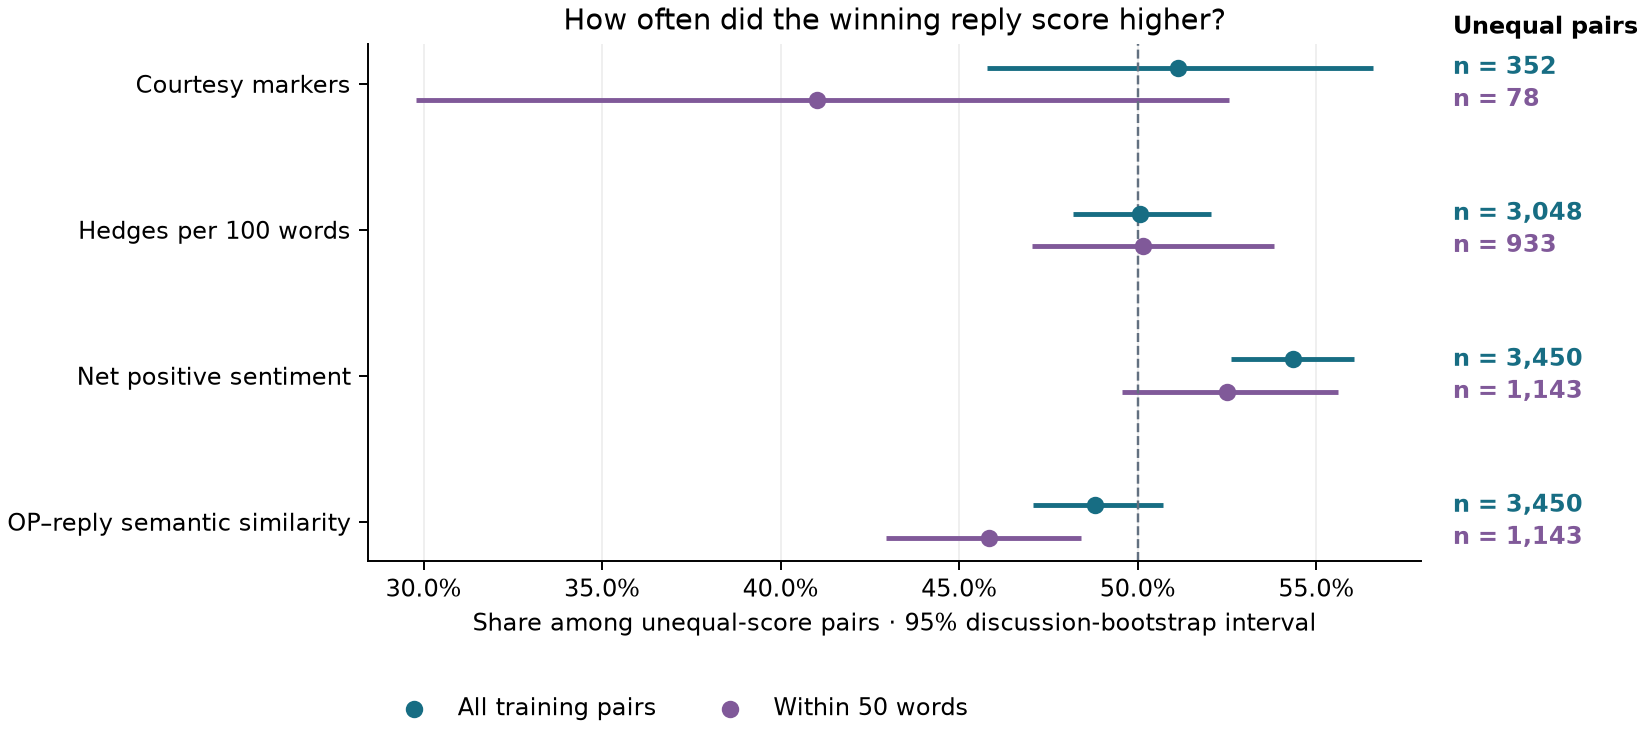

complete_pairs  ties  non_ties  mean_difference  mean_ci_low  mean_ci_high  median_difference  median_ci_low  median_ci_high  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
cohort             feature                                                                                                                                                                                                                    
All training pairs Courtesy markers                        3451  3099       352           0.0052      -0.0066        0.0183             0.0000         0.0000          0.0000              0.5114                0.4578                 0.5660
                   Hedges per 100 words                    3451   403      3048           0.0057      -0.0366        0.0484             0.0000         0.0000          0.0000              0.5007                0.4818                 0.5205
                   Net positive sentiment                  3451     1      3450           0.0312       0.0173        0.0444             0.0351         0.0220          0.0456              0.5435                0.5262                 0.5606
                   OP–reply semantic similarity            3451     1      3450          -0.0114      -0.0164       -0.0067            -0.0044        -0.0094          0.0019              0.4881                0.4708                 0.5070
Within 50 words    Courtesy markers                        1144  1066        78          -0.0114      -0.0281        0.0052             0.0000         0.0000          0.0000              0.4103                0.2978                 0.5255
                   Hedges per 100 words                    1144   211       933           0.0382      -0.0468        0.1348             0.0000         0.0000          0.0000              0.5016                0.4703                 0.5382
                   Net positive sentiment                  1144     1      1143           0.0186      -0.0083        0.0441             0.0210        -0.0017          0.0442              0.5249                0.4955                 0.5561
                   OP–reply semantic similarity            1144     1      1143          -0.0179      -0.0262       -0.0101            -0.0125        -0.0201         -0.0048              0.4584                0.4295                 0.4842

complete_pairs  ties  non_ties  mean_difference  mean_ci_low  mean_ci_high  median_difference  median_ci_low  median_ci_high  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
cohort             feature                                                                                                                                                                                                           
All training pairs sentiment_negative             3451     1      3450          -0.0249      -0.0337       -0.0156            -0.0229        -0.0310         -0.0130              0.4557                0.4382                 0.4734
                   sentiment_neutral              3451     1      3450           0.0186       0.0111        0.0259             0.0204         0.0124          0.0280              0.5426                0.5237                 0.5597
                   sentiment_positive             3451     1      3450           0.0063      -0.0001        0.0121             0.0036         0.0023          0.0048              0.5420                0.5256                 0.5585
                   Please                         3451  3347       104           0.0006      -0.0056        0.0069             0.0000         0.0000          0.0000              0.5096                0.4107                 0.6200
                   Please start                   3451  3416        35          -0.0009      -0.0046        0.0026             0.0000         0.0000          0.0000              0.4571                0.2758                 0.6429
                   HASHEDGE                       3451  2828       623           0.0281       0.0136        0.0428             0.0000         0.0000          0.0000              0.5778                0.5386                 0.6173
                   Indirect (btw)                 3451  3439        12           0.0035       0.0015        0.0059             0.0000         0.0000          0.0000              1.0000                1.0000                 1.0000
                   Hedges                         3451  1945      1506           0.0238      -0.0000        0.0476             0.0000         0.0000          0.0000              0.5272                0.5000                 0.5535
                   Factuality                     3451  1938      1513           0.0530       0.0292        0.0774             0.0000         0.0000          0.0000              0.5605                0.5335                 0.5882
                   Deference                      3451  3385        66           0.0000      -0.0047        0.0045             0.0000         0.0000          0.0000              0.5000                0.3833                 0.6154
                   Gratitude                      3451  3358        93           0.0026      -0.0032        0.0086             0.0000         0.0000          0.0000              0.5484                0.4400                 0.6630
                   Apologizing                    3451  3343       108           0.0041      -0.0017        0.0105             0.0000         0.0000          0.0000              0.5648                0.4722                 0.6699
                   1st person pl.                 3451  2054      1397           0.0536       0.0310        0.0758             0.0000         0.0000          0.0000              0.5662                0.5382                 0.5947
                   1st person                     3451  2047      1404           0.0446       0.0224        0.0669             0.0000         0.0000          0.0000              0.5548                0.5278                 0.5824
                   1st person start               3451  1968      1483           0.0374       0.0143        0.0610             0.0000         0.0000          0.0000              0.5435                0.5166                 0.5700
                   2nd person                     3451  2610       841           0.0246       0.0064        0.0430             0.0

In [2]:
display(Image(filename=str(run / "paired_strategy_differences.png")))
fields = [
    "complete_pairs", "ties", "non_ties", "mean_difference", "mean_ci_low", "mean_ci_high",
    "median_difference", "median_ci_low", "median_ci_high",
    "winner_higher_rate", "winner_higher_ci_low", "winner_higher_ci_high",
]
overall = stats.loc[stats["group_type"].eq("overall")].copy()
headline = overall.loc[overall["feature"].isin(labels)].replace({"feature": labels})
display(headline.set_index(["cohort", "feature"])[fields].round(4))

detail = overall.loc[~overall["feature"].isin(labels)].copy()
detail["feature"] = detail["feature"].str.removeprefix("strategy::")
display(detail.set_index(["cohort", "feature"])[fields].round(4))

## Topic × strategy

Each opening inherits its OP’s topic. The plot shows an unequal-pair win share, a discussion-bootstrap interval, and the number of pairs contributing to that cell. The [draft groups](../topics/topic_discovery.ipynb) are provisional and multiple comparisons make individual topic patterns exploratory. This plot does not test interactions.

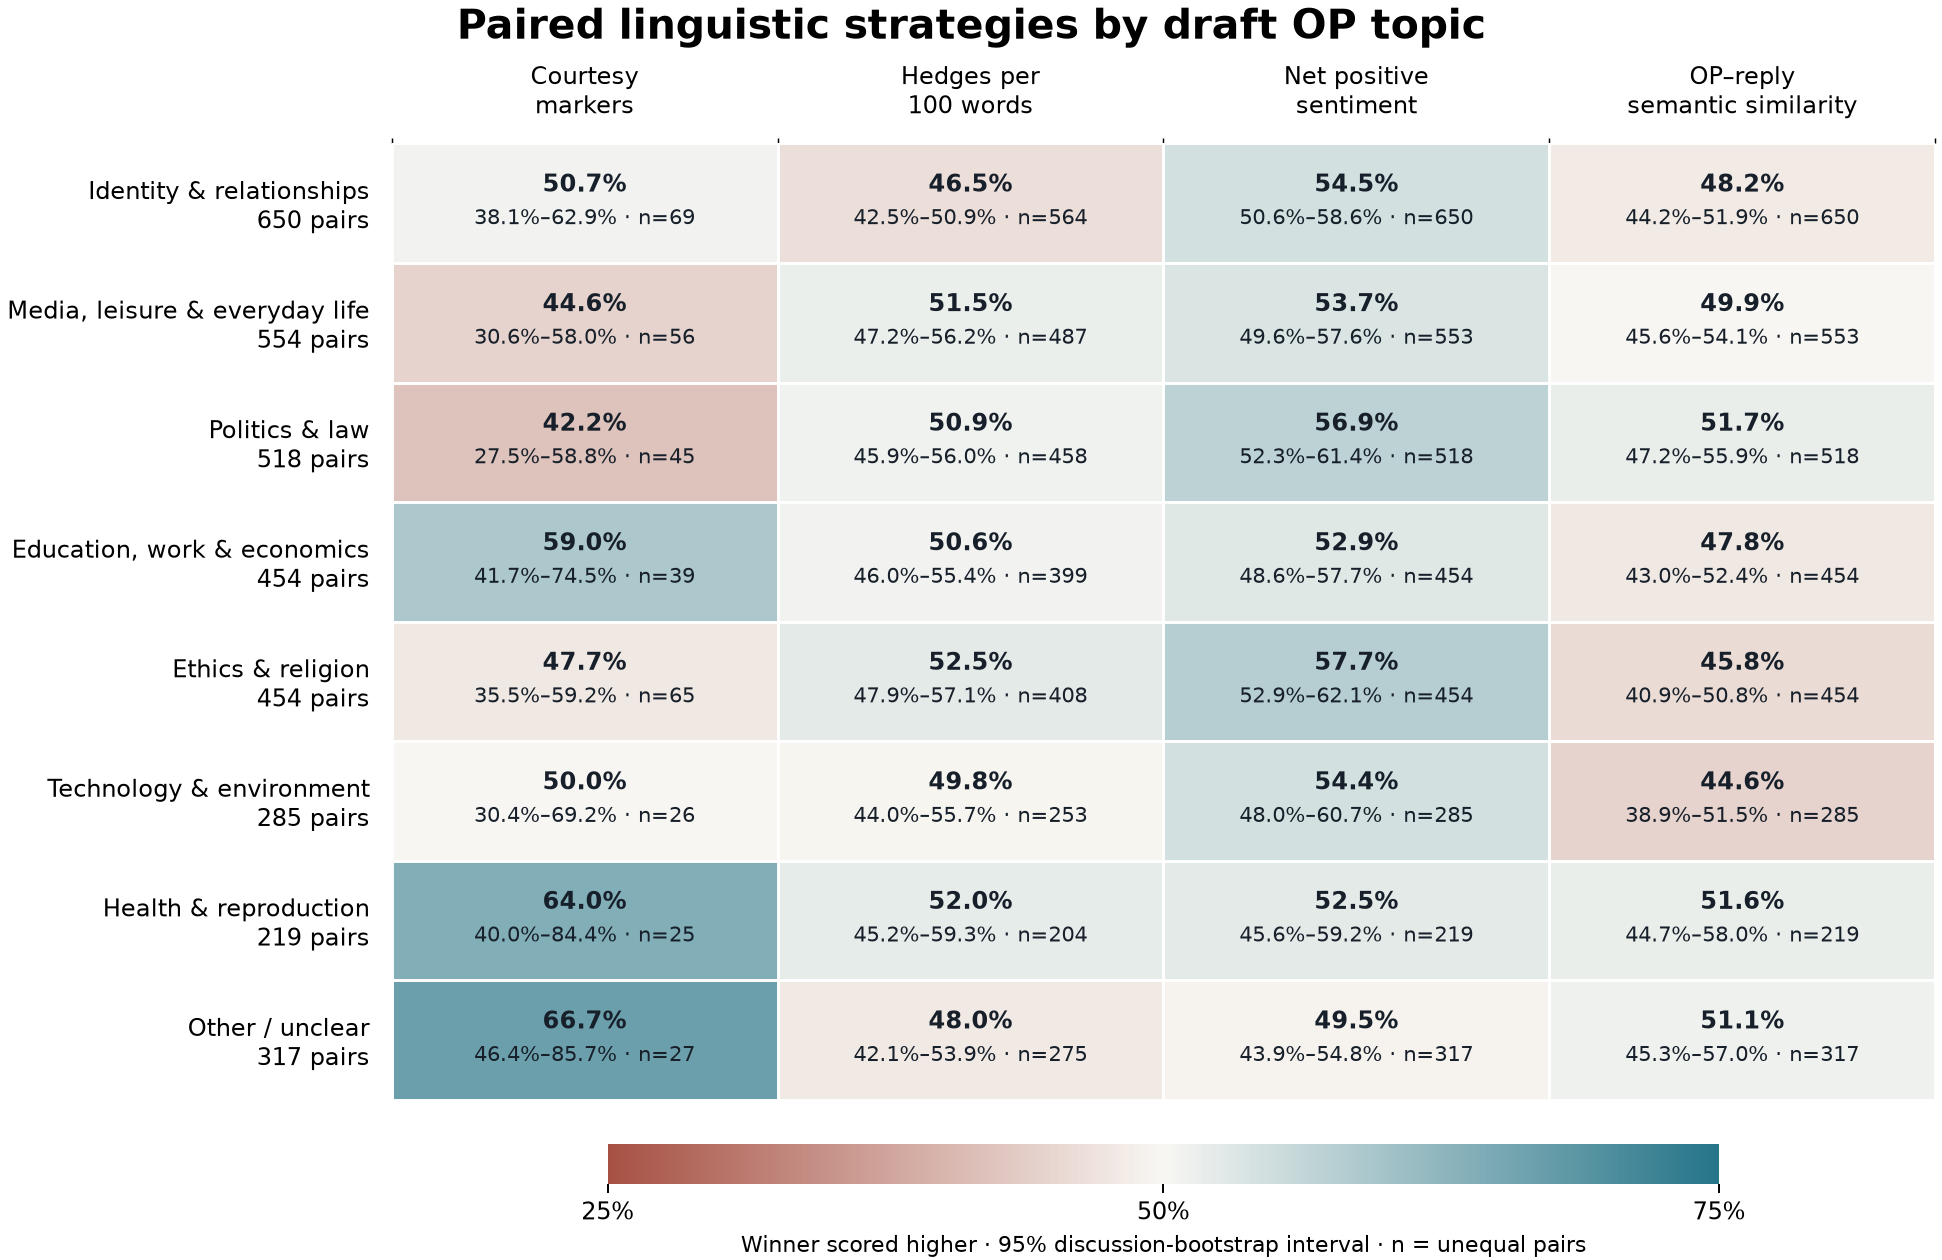

discussions  complete_pairs  ties  non_ties  mean_difference  mean_ci_low  mean_ci_high  median_difference  median_ci_low  median_ci_high  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
cohort                         feature                                                                                                                                                                                                                                 
Education, work & economics    Courtesy markers                      320             454   415        39           0.0176      -0.0113        0.0457             0.0000         0.0000          0.0000              0.5897                0.4167                 0.7448
                               Hedges per 100 words                  320             454    55       399          -0.0476      -0.1641        0.0686             0.0000         0.0000          0.0000              0.5063                0.4604                 0.5541
                               Net positive sentiment                320             454     0       454           0.0235      -0.0125        0.0619             0.0220        -0.0136          0.0574              0.5286                0.4861                 0.5769
                               OP–reply semantic similarity          320             454     0       454          -0.0180      -0.0303       -0.0058            -0.0113        -0.0235          0.0070              0.4780                0.4298                 0.5241
Ethics & religion              Courtesy markers                      323             454   389        65          -0.0044      -0.0445        0.0311             0.0000         0.0000          0.0000              0.4769                0.3553                 0.5916
                               Hedges per 100 words                  323             454    46       408           0.1242       0.0049        0.2487             0.0000         0.0000          0.0879              0.5245                0.4794                 0.5711
                               Net positive sentiment                323             454     0       454           0.0652       0.0315        0.0992             0.0567         0.0294          0.0935              0.5771                0.5288                 0.6206
                               OP–reply semantic similarity          323             454     0       454          -0.0175      -0.0307       -0.0039            -0.0138        -0.0246          0.0042              0.4581                0.4090                 0.5079
Health & reproduction          Courtesy markers                      150             219   194        25           0.0320      -0.0208        0.0909             0.0000         0.0000          0.0000              0.6400                0.4000                 0.8438
                               Hedges per 100 words                  150             219    15       204           0.0134      -0.1396        0.1628             0.0000        -0.0520          0.2861              0.5196                0.4520                 0.5929
                               Net positive sentiment                150             219     0       219           0.0246      -0.0282        0.0739             0.0235        -0.0236          0.0806              0.5251                0.4563                 0.5921
                               OP–reply semantic similarity          150             219     0       219          -0.0075      -0.0278        0.0114             0.0035        -0.0176          0.0172              0.5160                0.4466                 0.5801
Identity & relationships       Courtesy markers                      484             650   581        69           0.0077      -0.0224        0.0357             0.0000         0.0000          0.0000              0.5072                0.3809                 0.6286
                               Hedges per 100 words                  484             650    86       

Topic results for all individual features: /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/linguistic-features/paired-linguistic-strategy-summary/20261121T204851393276Z/paired_strategy_associations.csv


In [3]:
display(Image(filename=str(run / "topic_strategy_heatmap.png")))
topic = stats.loc[stats["group_type"].eq("topic")].copy()
display(topic.loc[topic["feature"].isin(labels)].replace({"feature": labels}).set_index(
    ["cohort", "feature"]
)[["discussions", *fields]].round(4))
print(f"Topic results for all individual features: {run / 'paired_strategy_associations.csv'}")

## Two replies to one OP

Show a seeded example from the length-matched subset with both archived word counts at most 180 and all four primary measures available. The table shows the metrics, strategies, and hedge matches next to the two cleaned openings.

In [4]:
from html import escape
from IPython.display import HTML

both = [f"{side}_{feature}" for side in ("a", "b") for feature in labels]
candidates = pairs.loc[
    pairs["within_50_words"] & pairs[["a_word_count", "b_word_count"]].max(axis=1).le(180)
].dropna(subset=both)
example = candidates.sample(1, random_state=42).iloc[0]
winner = "a" if example["a_wins"] else "b"
comparison = "b" if winner == "a" else "a"
metrics = pd.DataFrame({
    name: {label: example[f"{side}_{feature}"] for feature, label in labels.items()}
    for name, side in (("Winner", winner), ("Comparison", comparison))
})
display(metrics.round(4))
cards = []
for name, side in (("Winner", winner), ("Comparison", comparison)):
    comment = example[f"{side}_comment_id"]
    text = openings.at[comment, "opening_text"]
    markers = example[f"{side}_courtesy_examples"] or "None"
    hedges = example[f"{side}_hedge_examples"] or "None"
    cards.append(
        f"<div style='padding:12px;border:1px solid #d0d7de;border-radius:7px;min-width:0;flex:1'>"
        f"<strong>{name} · {example[f'{side}_word_count']} words</strong>"
        f"<p><b>Courtesy markers</b> {escape(markers)}<br><b>Hedge matches</b> {escape(hedges)}</p>"
        f"<div style='white-space:pre-wrap;overflow-wrap:anywhere'>{escape(text)}</div></div>"
    )
display(HTML(
    f"<h4>{escape(str(example['title']))}</h4><p>OP {example['post_id']} · {escape(example['broad_topic'])}</p>"
    f"<div style='display:flex;gap:12px;align-items:flex-start'>{''.join(cards)}</div>"
))

,Winner,Comparison
Courtesy markers,0.0000,0.0000
Hedges per 100 words,0.0000,0.0000
Net positive sentiment,-0.4817,-0.0127
OP–reply semantic similarity,0.2783,0.4986


Matched reply comparison

## What distinguished winners?

Winning openings showed modestly more positive net sentiment overall. The length-matched estimate was smaller and its interval included no difference. The courtesy summary was usually tied, and the normalized hedge count was near an even split in both samples.

Winning openings had slightly lower average OP–reply cosine similarity. The negative difference persisted in the length-matched sample, where winners scored higher in 45.8% of unequal pairs. The topic estimates vary, with substantial uncertainty in several groups. These are descriptive results from provisional topic labels and do not establish that an effect differs by topic.

For a future predictive test, semantic similarity is the clearest candidate to carry forward from this comparison. Interpret it as OP–reply semantic proximity. Net sentiment has a weaker length-matched result, and courtesy markers and hedges have limited support under these definitions.

The [adjusted P6 comparison](../models/p6_adjusted_linguistic_strategies.ipynb) tests the selected features together against P4.

## Three broad topic groups

Apply the [fixed eight-to-three mapping](broad_topic_groups.csv) by OP discussion. Keep Other / unclear separate. The archived pair scores and original topic assignments carry through to the grouped table. The [regrouping script](regroup_paired_linguistic_strategies.py) reuses existing scores and resamples OP discussions. The eight-topic heatmap above remains available for comparison.

,All pairs,Within 50 words
Society & Values,1841,618
"Work, Technology & Economics",739,255
Culture & Everyday Life,554,170
Other / unclear,317,101


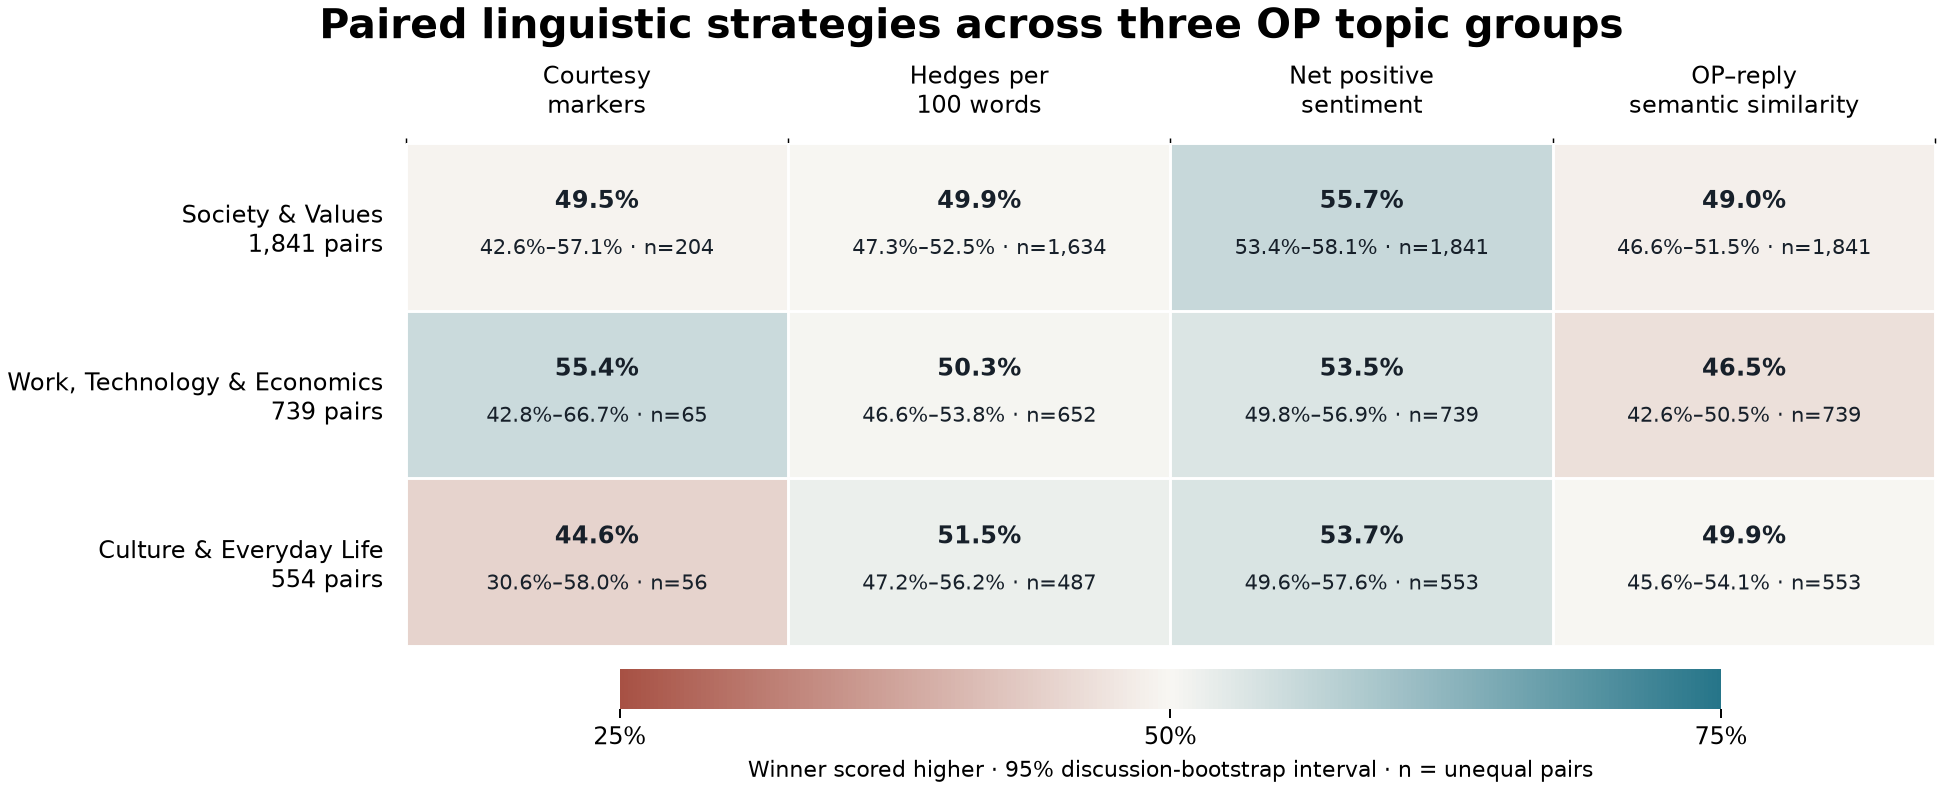

In [5]:
broad_path = sorted((DATA / "paired-linguistic-broad-topics").glob("*/results.json"))[-1]
broad_run = broad_path.parent
broad_report = json.loads(broad_path.read_text())
assert broad_report["split"] == "train" and broad_report["feature_run"] == report["feature_run"]
grouped_pairs = pd.read_parquet(broad_run / "pair_strategy_scores_with_topic_group.parquet")
pd.testing.assert_frame_equal(grouped_pairs[pairs.columns], pairs)
assert grouped_pairs.groupby("post_id")["topic_group"].nunique().eq(1).all()
coverage = pd.DataFrame({
    "All pairs": broad_report["pairs_by_topic_group"],
    "Within 50 words": broad_report["length_matched_pairs_by_topic_group"],
})
display(coverage)
display(Image(filename=str(broad_run / "broad_topic_strategy_heatmap.png")))

### All pairs and the 50-word subset

Report winner-minus-comparison means and medians in their original units. The winner-higher share uses unequal pairs. The intervals resample OP discussions. The supplemental table keeps Other / unclear visible.

In [6]:
broad = pd.read_csv(broad_run / "broad_topic_strategy_associations.csv")
report_fields = [
    "pairs", "discussions", "ties", "non_ties", "mean_difference", "mean_ci_low", "mean_ci_high",
    "median_difference", "median_ci_low", "median_ci_high",
    "winner_higher_rate", "winner_higher_ci_low", "winner_higher_ci_high",
]
named = broad["topic_group"].ne("Other / unclear")
for subset, label in ((named, "Three broad groups"), (~named, "Other / unclear supplement")):
    print(label)
    display(broad.loc[subset].replace({"feature": labels}).set_index(
        ["subset", "topic_group", "feature"],
    )[report_fields].round(4))

Three broad groups


pairs  discussions  ties  non_ties  mean_difference  mean_ci_low  mean_ci_high  median_difference  median_ci_low  median_ci_high  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
subset             topic_group                  feature                                                                                                                                                                                                                        
All training pairs Culture & Everyday Life      Courtesy markers                554          412   498        56          -0.0072      -0.0440        0.0246             0.0000         0.0000          0.0000              0.4464                0.3064                 0.5798
                                                Hedges per 100 words            554          412    67       487           0.0147      -0.0863        0.1152             0.0000         0.0000          0.0000              0.5154                0.4723                 0.5624
                                                Net positive sentiment          554          412     1       553           0.0191      -0.0173        0.0536             0.0358        -0.0076          0.0649              0.5371                0.4964                 0.5763
                                                OP–reply semantic similarity    554          412     1       553          -0.0054      -0.0159        0.0054            -0.0004        -0.0146          0.0107              0.4991                0.4559                 0.5405
                   Society & Values             Courtesy markers               1841         1349  1637       204           0.0027      -0.0141        0.0202             0.0000         0.0000          0.0000              0.4951                0.4257                 0.5714
                                                Hedges per 100 words           1841         1349   207      1634           0.0246      -0.0388        0.0827             0.0000         0.0000          0.0000              0.4988                0.4730                 0.5247
                                                Net positive sentiment         1841         1349     0      1841           0.0422       0.0247        0.0627             0.0402         0.0235          0.0555              0.5573                0.5339                 0.5810
                                                OP–reply semantic similarity   1841         1349     0      1841          -0.0112      -0.0175       -0.0048            -0.0033        -0.0095          0.0042              0.4900                0.4661                 0.5153
                   Work, Technology & Economics Courtesy markers                739          519   674        65           0.0108      -0.0111        0.0308             0.0000         0.0000          0.0000              0.5538                0.4285                 0.6667
                                                Hedges per 100 words            739          519    87       652          -0.0297      -0.1165        0.0570             0.0000         0.0000          0.0000              0.5031                0.4665                 0.5381
                                                Net positive sentiment          739          519     0       739           0.0301      -0.0007        0.0607             0.0311        -0.0026          0.0619              0.5345                0.4980                 0.5690
                                                OP–reply semantic similarity    739          519     0       739          -0.0182      -0.0280       -0.0084            -0.0129        -0.0218          0.0010              0.4655                0.4258                 0.5046
Within 50 words    Culture & Everyday Life      Courtesy markers                170          154   159        11           0.0059      -0.0301        0.0430             0.0000         0.0000          0.0000              0.5455                0.2222                 0.857

Other / unclear supplement


pairs  discussions  ties  non_ties  mean_difference  mean_ci_low  mean_ci_high  median_difference  median_ci_low  median_ci_high  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
subset             topic_group     feature                                                                                                                                                                                                                        
All training pairs Other / unclear Courtesy markers                317          227   290        27           0.0284      -0.0153        0.0706             0.0000         0.0000          0.0000              0.6667                0.4545                 0.8571
                                   Hedges per 100 words            317          227    42       275          -0.0374      -0.1920        0.1047             0.0000        -0.0161          0.0000              0.4800                0.4164                 0.5385
                                   Net positive sentiment          317          227     0       317          -0.0097      -0.0472        0.0304            -0.0056        -0.0498          0.0462              0.4953                0.4420                 0.5494
                                   OP–reply semantic similarity    317          227     0       317          -0.0073      -0.0249        0.0103             0.0015        -0.0209          0.0176              0.5110                0.4534                 0.5654
Within 50 words    Other / unclear Courtesy markers                101           86    95         6           0.0297      -0.0206        0.0891             0.0000         0.0000          0.0000              0.6667                0.2500                 1.0000
                                   Hedges per 100 words            101           86    21        80           0.0176      -0.2873        0.2984             0.0000        -0.0076          0.0152              0.5000                0.3846                 0.6154
                                   Net positive sentiment          101           86     0       101          -0.0578      -0.1227        0.0056            -0.0919        -0.1360         -0.0105              0.3861                0.2989                 0.4757
                                   OP–reply semantic similarity    101           86     0       101          -0.0186      -0.0458        0.0098            -0.0210        -0.0444          0.0106              0.4455                0.3542                 0.5481

### Direct contrasts between broad groups

The contrasts subtract group B's statistic from group A's statistic for each feature. OP discussions are resampled independently within each broad group, which retains within-discussion dependence and keeps the comparison groups fixed. Compare both unequal-pair winner-higher shares and mean paired differences. The 95% percentile intervals are exploratory and unadjusted for multiple comparisons.

In [7]:
contrasts = pd.read_csv(broad_run / "broad_topic_bootstrap_contrasts.csv").replace({"feature": labels})
contrast_fields = ["difference", "ci_low", "ci_high", "unequal_pairs_a", "unequal_pairs_b"]
for subset in contrasts["subset"].drop_duplicates():
    rates = contrasts.loc[contrasts["subset"].eq(subset) & contrasts["metric"].eq("winner_higher_rate")].copy()
    rates[["difference", "ci_low", "ci_high"]] *= 100
    print(f"{subset} · difference in percentage points")
    display(rates.set_index(["group_a", "group_b", "feature"])[contrast_fields].round(2))

print(f"All winner-share and raw-mean contrasts: {broad_run / 'broad_topic_bootstrap_contrasts.csv'}")

All training pairs · difference in percentage points


difference  ci_low  ci_high  unequal_pairs_a  unequal_pairs_b
group_a                      group_b                      feature                                                                                    
Society & Values             Work, Technology & Economics Courtesy markers                   -5.87  -19.50     8.54              204               65
                                                          Hedges per 100 words               -0.43   -4.91     3.99             1634              652
                                                          Net positive sentiment              2.28   -1.77     6.52             1841              739
                                                          OP–reply semantic similarity        2.45   -2.08     6.55             1841              739
                             Culture & Everyday Life      Courtesy markers                    4.87  -10.01    20.00              204               56
                                                          Hedges per 100 words               -1.66   -7.05     3.62             1634              487
                                                          Net positive sentiment              2.02   -2.54     6.77             1841              553
                                                          OP–reply semantic similarity       -0.91   -5.81     4.01             1841              553
Work, Technology & Economics Culture & Everyday Life      Courtesy markers                   10.74   -7.92    30.01               65               56
                                                          Hedges per 100 words               -1.23   -6.64     4.62              652              487
                                                          Net positive sentiment             -0.26   -5.63     5.22              739              553
                                                          OP–reply semantic similarity       -3.36   -8.91     2.27              739              553

Within 50 words · difference in percentage points


difference  ci_low  ci_high  unequal_pairs_a  unequal_pairs_b
group_a                      group_b                      feature                                                                                    
Society & Values             Work, Technology & Economics Courtesy markers                    1.07  -29.38    29.17               44               17
                                                          Hedges per 100 words                6.39   -1.41    15.04              511              205
                                                          Net positive sentiment             -6.19  -13.53     0.62              618              255
                                                          OP–reply semantic similarity        5.75   -1.33    13.27              618              255
                             Culture & Everyday Life      Courtesy markers                  -18.18  -52.98    16.19               44               11
                                                          Hedges per 100 words               -2.74  -11.52     6.84              511              137
                                                          Net positive sentiment             -5.35  -14.45     2.81              618              169
                                                          OP–reply semantic similarity       -2.78  -10.44     5.39              618              169
Work, Technology & Economics Culture & Everyday Life      Courtesy markers                  -19.25  -59.18    21.11               17               11
                                                          Hedges per 100 words               -9.14  -19.67     1.01              205              137
                                                          Net positive sentiment              0.84   -8.82     9.95              255              169
                                                          OP–reply semantic similarity       -8.53  -17.29     1.23              255              169

All winner-share and raw-mean contrasts: /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/linguistic-features/paired-linguistic-broad-topics/20261121T205414057984Z/broad_topic_bootstrap_contrasts.csv


### What the grouping can hide

Within each merged group, compare the smallest and largest winner-higher shares across its original topics. A range spanning 50% shows opposing point estimates and can be a reason to inspect the eight-topic heatmap. This check is descriptive. The confidence intervals in the original groups remain relevant.

In [8]:
detail = pd.read_csv(broad_run / "eight_topic_strategy_associations.csv")
merged_groups = ["Society & Values", "Work, Technology & Economics"]
ranges = detail.loc[detail["topic_group"].isin(merged_groups)].groupby(
    ["subset", "topic_group", "feature"]
)["winner_higher_rate"].agg(lowest="min", highest="max").reset_index().replace({"feature": labels})
ranges["Original estimates straddle 50%"] = ranges["lowest"].lt(0.5) & ranges["highest"].gt(0.5)
display(ranges.set_index(["subset", "topic_group", "feature"]).round(4))

lowest  highest  Original estimates straddle 50%
subset             topic_group                  feature                                                                       
All training pairs Society & Values             Courtesy markers              0.4222   0.6400                             True
                                                Hedges per 100 words          0.4645   0.5245                             True
                                                Net positive sentiment        0.5251   0.5771                            False
                                                OP–reply semantic similarity  0.4581   0.5174                             True
                   Work, Technology & Economics Courtesy markers              0.5000   0.5897                            False
                                                Hedges per 100 words          0.4980   0.5063                             True
                                                Net positive sentiment        0.5286   0.5439                            False
                                                OP–reply semantic similarity  0.4456   0.4780                            False
Within 50 words    Society & Values             Courtesy markers              0.0769   1.0000                             True
                                                Hedges per 100 words          0.4561   0.5489                             True
                                                Net positive sentiment        0.4722   0.5538                             True
                                                OP–reply semantic similarity  0.4295   0.5000                            False
                   Work, Technology & Economics Courtesy markers              0.1667   0.4545                            False
                                                Hedges per 100 words          0.4435   0.4556                            False
                                                Net positive sentiment        0.5607   0.5878                            False
                                                OP–reply semantic similarity  0.4112   0.4122                            False

### Interpretation

Winners scored higher on net sentiment in all three named groups. Among length-matched pairs, Work, Technology & Economics showed both higher sentiment and lower OP–reply similarity for winners. The direct contrasts leave differences between broad groups uncertain. Courtesy ties remain common, with only 44, 17, and 11 informative length-matched pairs across the three named groups.

Pooling can hide different directions: for example, Society & Values combines original topics with OP–reply similarity estimates on both sides of 50%. The broad groups support more precise descriptive summaries, while the original groups help show what those averages combine.

## Individual courtesy markers

Compare gratitude, deference, apologies, and “please” separately. Each marker indicates whether the reply uses that category at least once. The two positions of “please” count as one category. The existing courtesy count gives each detected category one point.

First, measure how often the reply with a marker wins among pairs where only one reply contains it. For the courtesy count, use pairs with different totals. Compare all training pairs and pairs within 50 words of each other. Then add each feature separately to P4 (word count, content-word frequency, reply delay, and external links) on the same discussion-grouped training folds. The 95% intervals resample whole discussions.

In [9]:
import sys

from threadpoolctl import threadpool_limits

analysis_root = REPO / "project/notebooks/linguistic-features"
for folder in ("models", "strategies"):
    location = str(analysis_root / folder)
    if location not in sys.path:
        sys.path.insert(0, location)

from summarize_paired_linguistic_strategies import intervals
from train_p6_adjusted_linguistic_strategies import (
    IDENTIFIERS, P4_FEATURES, P4_RUN, paired, summarize_predictions,
)

marker_features = {
    "Gratitude": "strategy::Gratitude",
    "Deference": "strategy::Deference",
    "Apology": "strategy::Apologizing",
    "Please": "strategy::Please",
}
markers = {}
for side in ("a", "b"):
    markers[side] = pairs[[f"{side}_{key}" for key in marker_features.values()]].set_axis(marker_features, axis=1)
    markers[side]["Please"] = markers[side]["Please"].combine(pairs[f"{side}_strategy::Please start"], max)
    markers[side]["Courtesy count"] = pairs[f"{side}_courtesy_count"]

differences = markers["a"] - markers["b"]
winner_differences = differences.mul(2 * pairs["a_wins"] - 1, axis=0)
assert np.isfinite(differences.to_numpy()).all()
archive = pd.read_parquet(P4_RUN / "oof_predictions.parquet").set_index("pair_id").loc[pairs["pair_id"]].reset_index()
pd.testing.assert_frame_equal(archive[IDENTIFIERS], pairs[IDENTIFIERS].reset_index(drop=True))
baseline = archive["oof_probability_a_wins"].to_numpy()

columns = ["winner_higher", "non_ties", "winner_higher_rate", "winner_higher_ci_low", "winner_higher_ci_high"]
with threadpool_limits(limits=1):
    reproduced, _ = paired.evaluate_differences(archive, archive[P4_FEATURES])
    np.testing.assert_allclose(reproduced, baseline, atol=1e-12, rtol=1e-10)
    for cohort, mask in (("All training pairs", pairs["a_wins"].notna()), ("Within 50 words", pairs["within_50_words"])):
        association = intervals(pairs.loc[mask], winner_differences.loc[mask]).set_index("feature")[columns]
        print(cohort)
        print(association.round(4).to_string())
        print()

    incremental = []
    for feature in differences:
        inputs = archive[P4_FEATURES].assign(courtesy_difference=differences[feature].to_numpy())
        predictions, _ = paired.evaluate_differences(archive, inputs)
        result = summarize_predictions(archive, baseline, predictions).set_index("metric").loc["ROC-AUC"]
        incremental.append(result.rename(feature))

print("P4 plus one courtesy feature at a time")
print(pd.DataFrame(incremental).rename(columns={"p6": "extended", "p6_minus_p4": "change"}).round(5).to_string())


All training pairs
                winner_higher  non_ties  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
feature                                                                                                 
Gratitude                  51        93              0.5484                0.4400                 0.6630
Deference                  33        66              0.5000                0.3833                 0.6154
Apology                    61       108              0.5648                0.4722                 0.6699
Please                     64       133              0.4812                0.3892                 0.5715
Courtesy count            180       352              0.5114                0.4578                 0.5660

Within 50 words
                winner_higher  non_ties  winner_higher_rate  winner_higher_ci_low  winner_higher_ci_high
feature                                                                                                 
Gratitude          

Apologies had the highest raw win share (61 of 108, 56.5%), followed by gratitude (51 of 93, 54.8%). In the similar-length subset, the estimate for every marker was below 50%, with only 18–27 pairs per marker. Every interval in both cohorts included 50%.

Deference had the largest estimated gain over P4 (+0.00012 ROC-AUC). Every marker's interval for the change included zero, as did the interval for the combined count. These exploratory results leave no clear winner among the courtesy markers and provide little evidence for adding one to P4.